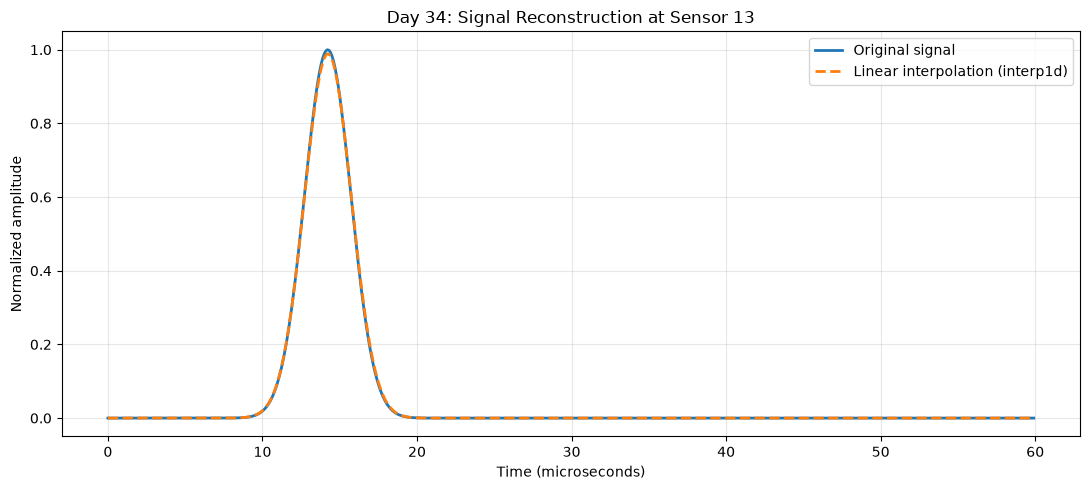

Day 34 completed.
Inactive sensors: 8 / 32
Missing data: 25.0%
Signal MAE: 0.00115346
Signal RMSE: 0.00413643
Maximum absolute error: 0.04299596
Plot saved to: ..\outputs\day34_interp1d_signal_comparison.png
Results saved to: ..\outputs\day34_interp1d_results.json


In [1]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# ==========================================
# Day 34: Linear Interpolation using interp1d
# ==========================================

# 1. Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Simulation parameters
num_sensors = 32
num_samples = 600

fs = 10e6
c = 1500.0

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

time = np.arange(num_samples) / fs
sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)

# 3. Generate the original signals
# Each sensor receives a Gaussian pulse based on its distance
signals_full = np.zeros((num_sensors, num_samples))

for i, sx in enumerate(sensor_x):
    distance = np.sqrt(
        (sx - source_x)**2 + source_y**2
    )

    arrival_time = distance / c

    signals_full[i, :] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

# 4. Simulate inactive sensors
inactive_indices = np.array(
    [1, 5, 9, 13, 17, 21, 25, 29]
)

active_mask = np.ones(num_sensors, dtype=bool)
active_mask[inactive_indices] = False

# The inactive sensors have no usable measurements
signals_missing = signals_full.copy()
signals_missing[inactive_indices, :] = np.nan

# 5. Linear interpolation with scipy.interpolate.interp1d
# axis=0 means interpolation is performed across sensor positions.
linear_interpolator = interp1d(
    sensor_x[active_mask],
    signals_full[active_mask, :],
    kind="linear",
    axis=0,
    bounds_error=False,
    fill_value="extrapolate"
)

# Preserve measured signals and estimate only missing sensors
signals_reconstructed = signals_missing.copy()

signals_reconstructed[inactive_indices, :] = (
    linear_interpolator(sensor_x[inactive_indices])
)

# 6. Calculate errors only at the inactive sensors
original_missing = signals_full[inactive_indices, :]
estimated_missing = signals_reconstructed[inactive_indices, :]

errors = estimated_missing - original_missing

mae = float(np.mean(np.abs(errors)))
rmse = float(np.sqrt(np.mean(errors**2)))
max_abs_error = float(np.max(np.abs(errors)))

# 7. Plot an example inactive sensor
# Sensor index 13 is inactive
sensor_to_plot = 13
sensor_position = np.where(
    inactive_indices == sensor_to_plot
)[0][0]

plt.figure(figsize=(11, 5))

plt.plot(
    time * 1e6,
    signals_full[sensor_to_plot],
    label="Original signal",
    linewidth=2
)

plt.plot(
    time * 1e6,
    signals_reconstructed[sensor_to_plot],
    "--",
    label="Linear interpolation (interp1d)",
    linewidth=2
)

plt.xlabel("Time (microseconds)")
plt.ylabel("Normalized amplitude")
plt.title(f"Day 34: Signal Reconstruction at Sensor {sensor_to_plot}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "day34_interp1d_signal_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 8. Save numerical results
results = {
    "day": 34,
    "method": "scipy.interpolate.interp1d",
    "interpolation": "linear",
    "num_sensors": int(num_sensors),
    "num_samples": int(num_samples),
    "sampling_frequency_hz": float(fs),
    "num_inactive_sensors": int(len(inactive_indices)),
    "inactive_sensor_indices": inactive_indices.tolist(),
    "missing_sensor_percentage": float(
        100 * len(inactive_indices) / num_sensors
    ),
    "evaluation_region": "inactive sensors only",
    "signal_mae": mae,
    "signal_rmse": rmse,
    "signal_max_absolute_error": max_abs_error
}

results_path = output_dir / "day34_interp1d_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("Day 34 completed.")
print(f"Inactive sensors: {len(inactive_indices)} / {num_sensors}")
print(f"Missing data: {results['missing_sensor_percentage']:.1f}%")
print(f"Signal MAE: {mae:.8f}")
print(f"Signal RMSE: {rmse:.8f}")
print(f"Maximum absolute error: {max_abs_error:.8f}")
print(f"Plot saved to: {output_dir / 'day34_interp1d_signal_comparison.png'}")
print(f"Results saved to: {results_path}")
